# EDA — partidos de las 5 grandes ligas (2014-15 a 2024-25)

Exploración breve del dataset de entrenamiento (`data/processed/matches.parquet`). **No se toca el holdout (2025-26).**
Toda la lógica reutilizable vive en `src/`; aquí solo se explora.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from betting_ml.domain.odds import overround  # noqa: E402

matches = pd.read_parquet(ROOT / "data/processed/matches.parquet")
print(matches.shape, matches["season"].min(), matches["season"].max())

(19837, 55) 2014-15 2024-25


## 1. Distribución de resultados (local / empate / visita) por liga

In [2]:
dist = pd.crosstab(matches["league"], matches["result"], normalize="index")[["H", "D", "A"]]
dist.round(3)

result,H,D,A
league,,,
D1,0.445,0.249,0.306
E0,0.446,0.234,0.320
F1,0.440,0.254,0.307
I1,0.424,0.260,0.316
SP1,0.454,0.260,0.286


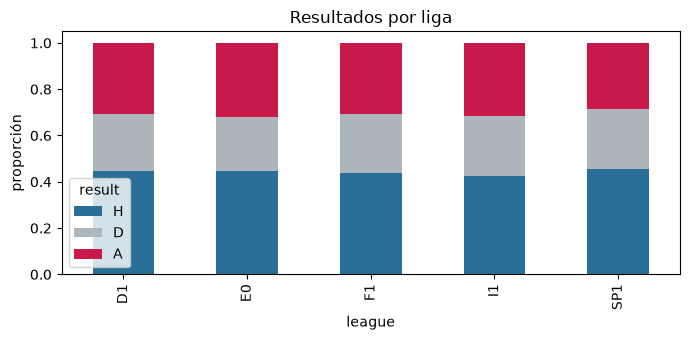

In [3]:
ax = dist.plot(kind="bar", stacked=True, figsize=(7, 3.5), color=["#2a6f97", "#adb5bd", "#c9184a"])
ax.set_ylabel("proporción"); ax.set_title("Resultados por liga"); plt.tight_layout()

In [4]:
# La temporada 2020-21 se jugó mayormente sin público: la ventaja de local cae.
pd.crosstab(matches["season"], matches["result"], normalize="index")[["H", "D", "A"]].round(3)

result,H,D,A
season,,,
2014-15,0.450,0.260,0.291
2015-16,0.444,0.259,0.297
2016-17,0.486,0.231,0.283
2017-18,0.453,0.245,0.302
2018-19,0.447,0.258,0.294
2019-20,0.441,0.243,0.315
2020-21,0.399,0.255,0.347
2021-22,0.428,0.258,0.314
2022-23,0.457,0.243,0.300


## 2. Margen promedio (overround) por casa

In [5]:
rows = []
for prefix, label in [("b365", "Bet365"), ("ps", "Pinnacle pre-cierre"), ("psc", "Pinnacle cierre"),
                      ("avg", "Promedio pre-cierre"), ("avgc", "Promedio cierre"), ("max", "Mejor cuota")]:
    cols = [f"{prefix}_odds_{s}" for s in "hda"]
    sub = matches[cols].dropna()
    rows.append({"casa": label, "partidos": len(sub), "margen_medio": overround(sub.to_numpy()).mean()})
pd.DataFrame(rows).round(4)

,casa,partidos,margen_medio
0,Bet365,19831,0.0513
1,Pinnacle pre-cierre,19815,0.0265
2,Pinnacle cierre,19835,0.0247
3,Promedio pre-cierre,19836,0.0482
4,Promedio cierre,10707,0.0450
5,Mejor cuota,19836,-0.0000


## 3. Goles vs xG

In [6]:
played = matches.dropna(subset=["home_xg", "away_xg"])
summary = played.groupby("league")[["home_goals", "home_xg", "away_goals", "away_xg"]].mean().round(2)
summary

,home_goals,home_xg,away_goals,away_xg
league,,,,
D1,1.69,1.66,1.34,1.32
E0,1.54,1.57,1.26,1.26
F1,1.49,1.49,1.19,1.18
I1,1.50,1.50,1.25,1.24
SP1,1.49,1.54,1.13,1.15


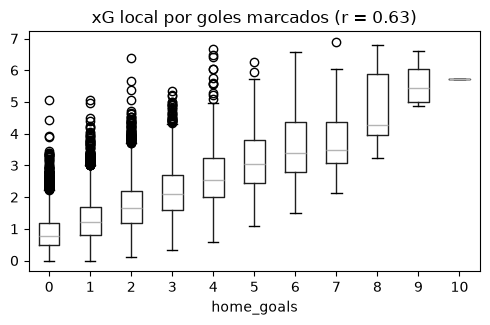

In [7]:
corr = np.corrcoef(played["home_goals"], played["home_xg"])[0, 1]
fig, ax = plt.subplots(figsize=(5, 3.5))
played.boxplot(column="home_xg", by="home_goals", ax=ax, grid=False)
ax.set_title(f"xG local por goles marcados (r = {corr:.2f})"); plt.suptitle(""); plt.tight_layout()

## 4. Evolución del Elo de 3 equipos

Elo exploratorio sencillo (K=20, ventaja local 60, sin regresión entre temporadas) solo para visualizar.
La implementación oficial y testeada está en `src/betting_ml/ml/features/elo.py` (T013).

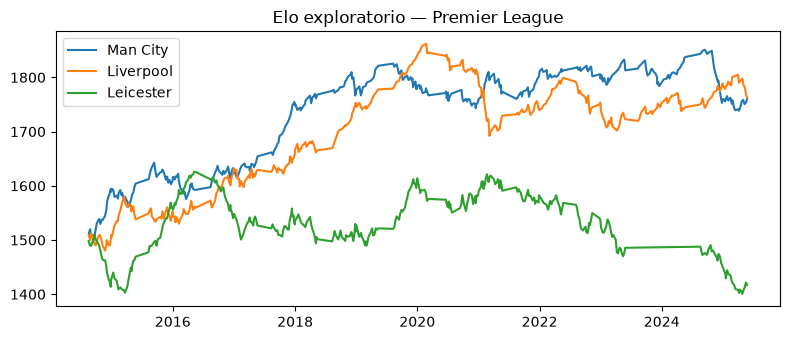

In [8]:
def quick_elo(df, k=20.0, home_adv=60.0):
    ratings, history = {}, []
    for row in df.sort_values("kickoff_utc").itertuples():
        rh, ra = ratings.get(row.home_team, 1500.0), ratings.get(row.away_team, 1500.0)
        expected = 1 / (1 + 10 ** ((ra - rh - home_adv) / 400))
        score = 1.0 if row.result == "H" else 0.5 if row.result == "D" else 0.0
        ratings[row.home_team] = rh + k * (score - expected)
        ratings[row.away_team] = ra - k * (score - expected)
        history += [(row.date, row.home_team, ratings[row.home_team]),
                    (row.date, row.away_team, ratings[row.away_team])]
    return pd.DataFrame(history, columns=["date", "team", "elo"])

elo = quick_elo(matches[matches["league"] == "E0"])
fig, ax = plt.subplots(figsize=(8, 3.5))
for team in ["Man City", "Liverpool", "Leicester"]:
    s = elo[elo["team"] == team]
    ax.plot(s["date"], s["elo"], label=team)
ax.legend(); ax.set_title("Elo exploratorio — Premier League"); plt.tight_layout()

## Hallazgos

- Local gana ~44–45 %, empate ~23–26 %, visita ~29–32 %. LaLiga tiene la mayor ventaja local; la Serie A, la menor y más empates.
- En 2020-21 (sin público) la victoria local cayó a ~40 % y la visitante subió a ~35 %: la ventaja de local no es constante y el Elo debería capturarlo con datos recientes.
- Margen medio: Pinnacle ~2.5–2.7 %, promedio del mercado ~4.8 %, Bet365 ~5.1 %. La "mejor cuota" entre casas tiene margen ≈ 0 %: apostar a la mejor casa equivale a jugar casi sin margen (clave para la spec 002).
- xG promedio ≈ goles promedio en todas las ligas (sesgo < 0.05 goles por partido): Understat está bien calibrado, y la Bundesliga es la liga más goleadora.
- La relación goles–xG por partido es fuerte pero ruidosa: xG es buen candidato para estimar la fuerza con menos ruido que los goles.
- El Elo refleja bien los ciclos (auge de Liverpool 2018-20, dominio de City, caída del Leicester tras 2016).
- El log loss del mercado promedio pre-cierre (Shin) sobre 2014-25 es ≈ 0.966: esa es la vara de referencia realista.